# Naive Bayes Classification to Predict Titanic Survival

**Deep Dive Coding Data Science Bootcamp Sample Project**

---
Robert Citek - October 5th, 2026


## Problem Definition

State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.

### Regression

For a regression, the Age will be the target.


## Data Collection/Sources

### Data Overview

This data comes from [Kaggle](https://www.kaggle.com/c/titanic/data), which was then copied to AWS for easy access.

https://ddc-datascience.s3.amazonaws.com/Projects/Example/Data/Titanic.train.csv


### Imports

In [1]:
from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

### File Paths

Create a variable `url` that contains the web link to the CSV data

In [2]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Example/Data/Titanic.train.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Example/Data/Titanic.train.csv'

### Load data

Load the data into a data frame named `titanic_df`.

In [3]:
# load data
titanic_df = pd.read_csv( url , usecols=['Age','Fare'])
titanic_df

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
886,27.0,13.0000
887,19.0,30.0000
888,NaN,23.4500
889,26.0,30.0000


### head

Look at the first few rows

In [4]:
# first few rows
titanic_df.head()

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


### tail

Look at the last few rows


In [5]:
# last few rows
titanic_df.tail()

,Age,Fare
886,27.0,13.00
887,19.0,30.00
888,NaN,23.45
889,26.0,30.00
890,32.0,7.75


### shape


In [6]:
# shape of data frame
titanic_df.shape

(891, 2)

### size


In [7]:
# size of data frame
titanic_df.size

1782

### Summary meta-data

Run the `info()` method on the data frame.


In [8]:
# display meta-data
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     714 non-null    float64
 1   Fare    891 non-null    float64
dtypes: float64(2)
memory usage: 14.1 KB


### Summary statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

Run the `describe()` method on the data frame.

In [9]:
# display summary statistics
titanic_df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


### target value_counts()


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [10]:
# look for nulls in the target
target_col = titanic_df['Age']
target_col.value_counts(dropna=False)

,count
Age,
NaN,177
24.00,30
22.00,27
18.00,26
28.00,25
...,...
24.50,1
0.67,1
0.42,1


In [11]:
# Drop rows that contain nulls in the target
titanic_df = titanic_df.dropna(axis=0, subset=titanic_df.columns[0])

In [12]:
# Verify that it removed the columns
titanic_df.shape

(714, 2)

### Nulls



In [13]:
# look for nulls
titanic_df['Fare'].isnull().sum()
# No nulls in the feature column

np.int64(0)

In [14]:
# look for nulls, displaying relative frequency
titanic_df.isnull().mean().sort_values(ascending=False)

,0
Age,0.0
Fare,0.0


### dtypes - column data types

Which data types would be appropriate for Linear Regression?


In [15]:
# display data types
titanic_df.dtypes

,0
Age,float64
Fare,float64


### Unique elements


If the total number of unique items in a field equals the number of rows, that suggests those fields are unique IDs ( e.g. names, IDs ) and should be dropped.


In [16]:
# number of unique elements in a column
titanic_df.nunique().sort_values(ascending=False) / titanic_df.size * 100

,0
Fare,15.406162
Age,6.162465


## Data Cleaning


### Backup #1


In [17]:
# make backup
titanic_df_bak1 = titanic_df.copy()

In [18]:
# restore from backup
titanic_df = titanic_df_bak1.copy()

### Keep only the target and two features

Select `Age` for the target and `Fare` for the feature

In [19]:
# select the target and one feature
target = titanic_df[['Age']]
feature = titanic_df[['Fare']]

In [20]:
# Verify the target
target

,Age
0,22.0
1,38.0
2,26.0
3,35.0
4,35.0
...,...
885,39.0
886,27.0
887,19.0
889,26.0


In [21]:
 # Verify the feature
 feature

,Fare
0,7.2500
1,71.2833
2,7.9250
3,53.1000
4,8.0500
...,...
885,29.1250
886,13.0000
887,30.0000
889,30.0000


### Backup #2


In [22]:
# make backup
titanic_df_bak2 = titanic_df.copy()

In [23]:
# restore from backup
titanic_df = titanic_df_bak2.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.


#### Impute

No imputation needed. Already looked at the target and culled nulls for the working dataframe.




In [24]:
# Calculate the median


In [25]:
# Assign median to nulls



In [26]:
# Verify there are no nulls
titanic_df.isnull().sum()

,0
Age,0
Fare,0


In [27]:
# Verify median is about the same as before


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

### ===START HERE=== correlated with the target


In [30]:
# Calculate a correlation matrix for the target
corr_mat = titanic_df.corr()
corr_mat

,Age,Fare
Age,1.000000,0.096067
Fare,0.096067,1.000000


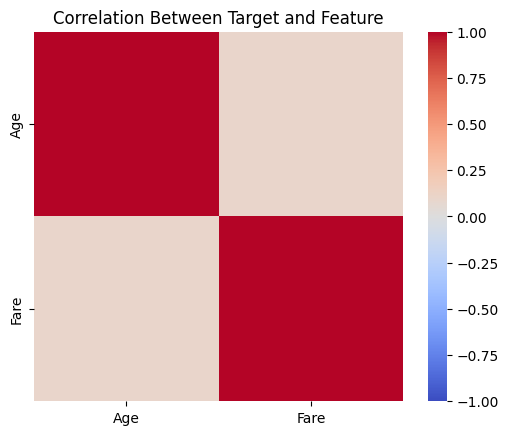

In [33]:
# Display the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=False,
    fmt='d',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Correlation Between Target and Feature');

In [34]:
# Create a data series with features ranked by correlation

### independence of features: correlation

In [34]:
# Calculate a correlation matrix for the features
corr_mat_feature = feature.corr()

In [35]:
# Display the correlation matrix
corr_mat_feature

,Fare
Fare,1.0


In [ ]:
# Create a data series with features ranked by correlation


## Processing


## Residual analysis


## Communication of Results

Conclusion:

Future work:


